# BrushCue Example: Crop Image

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/crop_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/crop-image

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


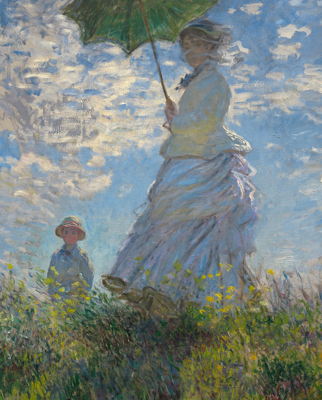

In [1]:
import io
from PIL import Image

import brushcue as bc

left = 0.1
top = 0.1
right = 0.9
bottom = 0.9
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
w = input_bounds.width()
h = input_bounds.height()
unit = w.min(h)
x0 = (input_bounds.min_x() + (w * bc.Float.min(left, right))).round_to_int().to_float()
y0 = (input_bounds.min_y() + (h * bc.Float.min(top, bottom))).round_to_int().to_float()
x1 = (input_bounds.min_x() + (w * bc.Float.max(left, right))).round_to_int().to_float()
y1 = (input_bounds.min_y() + (h * bc.Float.max(top, bottom))).round_to_int().to_float()
crop_bounds = bc.Bounds2f.from_x_y_width_height(
    x0, y0, (x1 - x0).max(1.0), (y1 - y0).max(1.0)
)
graph = input_image.crop(crop_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
